In [19]:
import pandas as pd

df = pd.read_csv("Depot_sales.csv", header=0, parse_dates=["date"])

print(df["Product_A"])

0       44.0
1       40.0
2       40.0
3       42.0
4       41.0
        ... 
1456    45.0
1457    44.0
1458    43.0
1459    45.0
1460    47.0
Name: Product_A, Length: 1461, dtype: float64


In [20]:
from scipy import stats 

print("Are these products sale values normally distributed")

test_a, pa = stats.shapiro(df["Product_A"])
test_b, pb = stats.shapiro(df["Product_B"])
test_c, pc = stats.shapiro(df["Product_C"])

if test_a > 0.05:
    print("Product A's sales are normally distributed")
else:
    print("Product A's sales are not normally distributed")

if test_b > 0.05:
    print("Product B's sales are normally distributed")
else:
    print("Product B's sales are not normally distributed")

if test_c > 0.05:
    print("Product C's sales are normally distributed")
else:
    print("Product C's sales are not normally distributed")

Are these products sale values normally distributed
Product A's sales are normally distributed
Product B's sales are normally distributed
Product C's sales are normally distributed


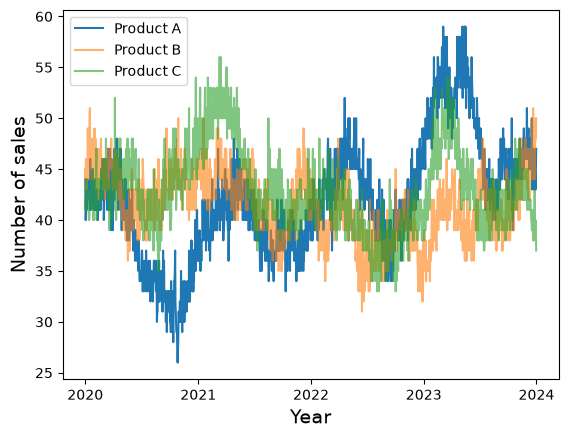

In [21]:
from matplotlib import pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots()
ax.plot(df["date"], df["Product_A"], label="Product A")
ax.plot(df["date"], df["Product_B"], label ="Product B",alpha = 0.6)
ax.plot(df["date"], df["Product_C"], label="Product C", alpha= 0.6)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()



### I perform the one way ANOVA to identify whether the means of the different product are significantly different. I test at p = 0.05 level of significance

In [22]:
stats.f_oneway(df["Product_A"], df["Product_B"], df["Product_C"])

F_onewayResult(statistic=np.float64(47.323767913712196), pvalue=np.float64(4.6393799294154e-21))

### As p is less than 0.05 the null hypothesis is rejected showing that the mean values of the three products are different to a statistically significant degree.

In [27]:
import numpy as np

#df_2020 = df[df["date"].dt.year == 2020]

yearly_means = (
    df.groupby(df["date"].dt.year)[["Product_A", "Product_B", "Product_C"]]
    .mean()
    .rename_axis("Year")
    .round(2)
)
yearly_means

,Product_A,Product_B,Product_C
Year,,,
2020,37.40,43.19,43.27
2021,39.37,42.24,45.15
2022,42.29,38.50,39.62
2023,48.60,41.13,43.45


### Performing a simple linear regression fit using generalised least squares to predict future price behaviour.

Slope: 0.0081 days (2.97 per year)
Intercept: 35.99
R2: 0.347, p-value: 2.52e-137


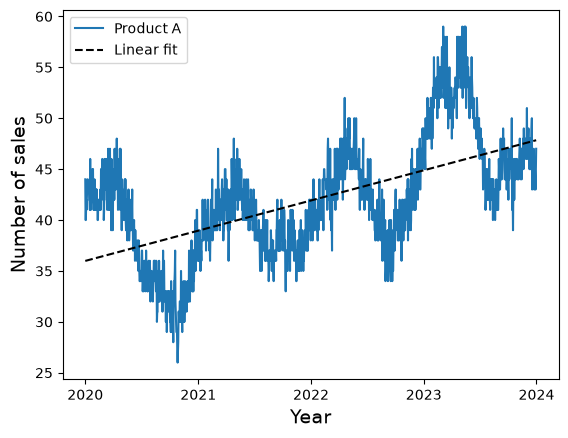

In [28]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

x = (df["date"] - df["date"].iloc[0]).dt.days

result = stats.linregress(x, df["Product_A"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
#print(f"least squares mean: {np.mean(fit_line):.2f}")
      
fig, ax = plt.subplots()
ax.plot(df["date"], df["Product_A"], label="Product A",)
ax.plot(df["date"], fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

Slope: -0.0027 days (-0.98 per year)
Intercept: 43.21
R2: 0.116, p-value: 7.15e-41


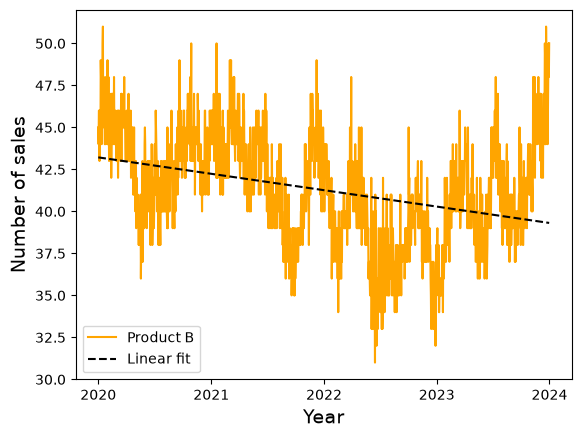

In [29]:
x = (df["date"] - df["date"].iloc[0]).dt.days

result = stats.linregress(x, df["Product_B"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
#print(f"least squares mean: {np.mean(fit_line):.2f}")
      
fig, ax = plt.subplots()
ax.plot(df["date"], df["Product_B"], label="Product B", color="orange")
ax.plot(df["date"], fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

Slope: -0.0022 days (-0.81 per year)
Intercept: 44.48
R2: 0.055, p-value: 1.47e-19


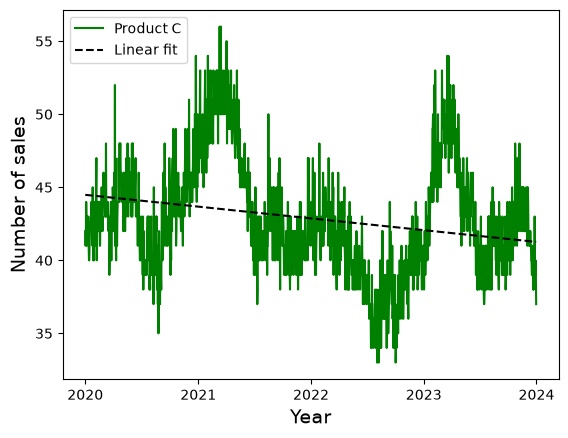

In [30]:
x = (df["date"] - df["date"].iloc[0]).dt.days

result = stats.linregress(x, df["Product_C"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
#print(f"least squares mean: {np.mean(fit_line):.2f}")
      
fig, ax = plt.subplots()
ax.plot(df["date"], df["Product_C"], label="Product C", color="green")
ax.plot(df["date"], fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

### The linear fits do give good results for mean (based off the regression fit) and low p-values but clearly miss a significant amount of the behaviour of the curve, though they are cheap to calculate.

In [ ]:
from statsmodels.tsa.holtwinters import Holt



const            35.318671
trend             0.008411
sin(1,364.99)     5.152109
cos(1,364.99)     0.365173
dtype: float64
MAE: 2.806668801285249


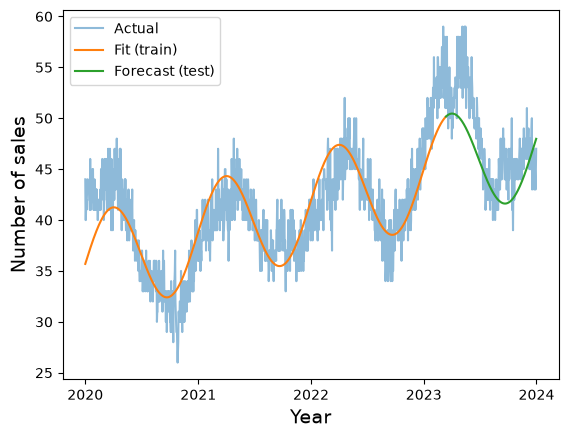

In [45]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier

df = pd.read_csv("Depot_sales.csv", parse_dates=["date"], index_col="date")
df = df.asfreq("D")                       # gives the index a daily frequency

PERIOD = 2 * np.pi * 58.09                   # ~365 days to 2 d.p.
split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]

dp = DeterministicProcess(
    train.index,
    constant=True,
    order=1,                              # 1 = linear trend
    additional_terms=[Fourier(period=PERIOD, order=1)],   # order = number of harmonics K
)

X_train = dp.in_sample()                  # const, trend, sin(1,P), cos(1,P)
X_test = dp.out_of_sample(steps=len(test))
X_test.index = test.index                 # align the forecast rows with the test dates

model = sm.OLS(train["Product_A"], X_train).fit(cov_type="HAC", cov_kwds={"maxlags": 30})
pred = model.predict(X_test)

print(model.params)
print("MAE:", np.mean(np.abs(test["Product_A"] - pred)))

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], alpha=0.5, label="Actual")
ax.plot(train.index, model.fittedvalues, label="Fit (train)")
ax.plot(test.index, pred, label="Forecast (test)")
ax.legend()
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()